# Día 1 — Datos, visualización y regresión lineal

**Módulo 3: Machine Learning Aplicado — CEC EPN / Banco Central del Ecuador**  
**Fecha:** 13-10-2026

Este notebook está escrito como **material de estudio**, no como una colección de comandos. La regla será siempre:

> **pregunta → datos → exploración → preparación → modelo → métricas → diagnóstico → decisión**


## Objetivos de la jornada

Al terminar deberías poder explicar, con tus propias palabras:

- para qué sirven **NumPy, Pandas, Matplotlib y Scikit-learn**;
- cómo saber **qué contiene realmente un dataset** antes de modelar;
- qué significan **X**, **y**, **intercepto** y **coeficiente**;
- cómo se obtiene una recta de regresión simple y qué minimiza;
- qué responden MAE, MSE, RMSE, Bias y R²;
- por qué separamos **Train, Validation y Test**;
- cómo pasar de una recta 2D a un plano 3D y luego a una regresión con muchas variables;
- cómo convertir categorías a números sin inventar un orden;
- por qué **asociación/predicción no equivalen a causalidad**.

## 0. Librerías que usaremos

Partimos de **Anaconda + Jupyter** ya instalados. No habrá un instalador automático dentro del notebook.

Si al ejecutar la siguiente celda aparece un error de módulo faltante, puedes instalar únicamente ese paquete desde una celda nueva, por ejemplo:

```python
%pip install statsmodels openpyxl
```

Después reinicia el kernel si Jupyter lo solicita y vuelve a ejecutar la celda de imports.

In [1]:
# Cálculo numérico y datos tabulares
import numpy as np
import pandas as pd

# Visualización
import matplotlib.pyplot as plt

# Rutas y utilidades estándar de Python
from pathlib import Path

# Machine Learning
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.preprocessing import StandardScaler

# Inferencia estadística complementaria
import statsmodels.api as sm

### ¿Por qué todos los imports están juntos?

Así podemos ver de una sola vez las herramientas que requiere la clase. Un `import` **no entrena ningún modelo**: solo hace disponible código escrito por otras bibliotecas.

- `numpy` y `pandas` preparan datos;
- `matplotlib` los dibuja;
- `sklearn` aporta algoritmos y métricas;
- `statsmodels` complementa con inferencia estadística;

In [2]:
# Ubicamos la carpeta de datos sin depender de si Jupyter se abrió
# desde la carpeta raíz o desde la carpeta notebooks/.
DATA_DIR = Path('../datos')
if not DATA_DIR.exists():
    DATA_DIR = Path('datos')

print('Usando datos desde:', DATA_DIR.resolve())

Usando datos desde: C:\Users\Usuario iTC\Desktop\modulo3_ml\datos


# 1. Antes del ML: NumPy, Pandas y Matplotlib

Machine Learning trabaja con números organizados en vectores y matrices. Por eso empezamos por las herramientas que representan, resumen y visualizan esos datos.

## 1.1 NumPy: vectores, matrices y operaciones numéricas

NumPy aporta el tipo `ndarray`. Una idea importante es que muchas operaciones se aplican **a todo el vector a la vez**, sin escribir un `for`.

In [3]:
# Un vector: una sola dimensión.
ventas = np.array([105, 112, 118, 109, 125])

print('Vector:', ventas)
print('Número de dimensiones:', ventas.ndim)
print('Forma:', ventas.shape)
print('Promedio:', ventas.mean())
print('Desviación estándar:', ventas.std().round(2))

Vector: [105 112 118 109 125]
Número de dimensiones: 1
Forma: (5,)
Promedio: 113.8
Desviación estándar: 7.03


In [4]:
# Vectorización: sumamos 10 a todos los elementos.
ventas_ajustadas = ventas + 10
ventas_lista = [105, 112, 118, 109, 125]
ventas_lista = ventas_lista * 2
# Operación elemento a elemento.
crecimiento_relativo = (ventas_ajustadas - ventas) / ventas

print('Ventas como una lista con ajuste:', ventas_lista)
print('Ventas ajustadas:', ventas_ajustadas)
print('Cambio relativo:', np.round(crecimiento_relativo, 3))

Ventas como una lista con ajuste: [105, 112, 118, 109, 125, 105, 112, 118, 109, 125]
Ventas ajustadas: [115 122 128 119 135]
Cambio relativo: [0.095 0.089 0.085 0.092 0.08 ]


En Machine Learning trabajamos más con matrices que con vectores para ello solemos dividir un dataset (conjunto de datos en forma de tabla) en X y Y, `X` suele ser una **matriz** que contiene los datos y variables con los que se realizará la predicción: filas = observaciones y columnas = variables. Veamos una matriz 3 × 2.

In [5]:
# Tres observaciones y dos variables.
X_demo = np.array([
    [100, 60],
    [120, 65],
    [140, 70]
])

print(X_demo)
print('Filas y columnas:', X_demo.shape)

[[100  60]
 [120  65]
 [140  70]]
Filas y columnas: (3, 2)


`shape = (3, 2)` significa **3 observaciones y 2 variables**. Esta notación será fundamental cuando usemos `X_train.shape`.

## 1.2 Pandas: una tabla con significado

NumPy sabe operar con números. Pandas añade nombres de columnas, fechas, categorías, índices y herramientas de limpieza. Su estructura principal es el **DataFrame**.

In [6]:
# Creamos una tabla mínima para reconocer la estructura DataFrame.
ejemplo = pd.DataFrame({
    'mes': ['ene', 'feb', 'mar'],
    'inversion_mill': [100, 120, 140],
    'crecimiento_pct': [1.1, 1.6, 2.0]
})

ejemplo

,mes,inversion_mill,crecimiento_pct
0,ene,100,1.1
1,feb,120,1.6
2,mar,140,2.0


Observa la diferencia con la matriz NumPy: ahora cada columna tiene **nombre y significado**. Esto facilita limpiar, filtrar y seleccionar variables.

## 1.3 Matplotlib: ver antes de modelar

Antes de construir un modelo de Machine Learning debemos **entender los datos**.

Una tabla nos permite conocer los valores exactos y una métrica puede resumir parte de la información, pero un gráfico puede mostrar comportamientos que serían difíciles de detectar únicamente observando números.

Por ejemplo, mediante gráficos podemos identificar:

- tendencias a lo largo del tiempo;
- relaciones entre dos variables;
- concentraciones de valores;
- distribuciones asimétricas;
- observaciones poco frecuentes o extremas;
- grupos de observaciones;
- relaciones no lineales;
- cambios en la variabilidad de los datos.

Para crear gráficos utilizaremos principalmente **Matplotlib**.

Matplotlib es una biblioteca de Python destinada a la visualización de datos. Normalmente la importamos de esta manera:

```python
import matplotlib.pyplot as plt
```

En esta sección estudiaremos cuatro gráficos básicos:


| Gráfico    | Función en Matplotlib | Principal pregunta que responde |
| ---------- | --------------------- | -------------------------------- |
| Línea      | `plt.plot()`          | ¿Cómo cambia una variable a lo largo del tiempo? |
| Histograma | `plt.hist()`          | ¿Cómo se distribuyen los valores de una variable? |
| Scatter    | `plt.scatter()`       | ¿Qué relación parece existir entre dos variables? |
| Boxplot    | `plt.boxplot()`       | ¿Cómo se distribuyen los datos y existen valores extremos? |.

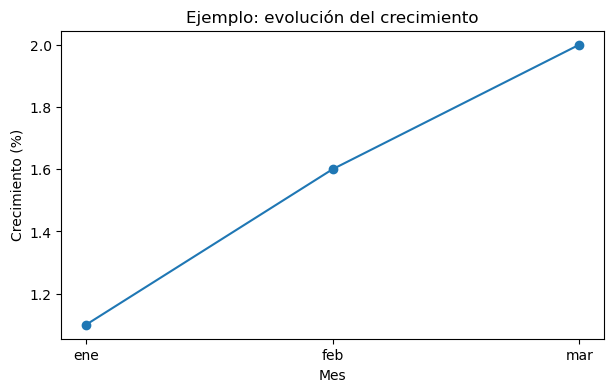

In [7]:
# Gráfico de línea sencillo.
# Creamos una nueva figura donde se dibujará el gráfico.
# figsize=(7, 4) indica el tamaño de la figura:
# 7 pulgadas de ancho y 4 pulgadas de alto.
plt.figure(figsize=(7, 4))


# plt.plot() crea un gráfico de línea.
#
# El primer argumento corresponde al eje X:
# ejemplo['mes']
#
# El segundo argumento corresponde al eje Y:
# ejemplo['crecimiento_pct']
#
# marker='o' agrega un círculo en cada observación
# para poder distinguir los puntos originales de la línea.
plt.plot(
    ejemplo['mes'],
    ejemplo['crecimiento_pct'],
    marker='o'
)


# Coloca el texto que describe el eje horizontal X.
# En este caso, X representa el mes de observación.
plt.xlabel('Mes')


# Coloca el texto que describe el eje vertical Y.
# En este caso, Y representa el porcentaje de crecimiento.
plt.ylabel('Crecimiento (%)')


# Agrega un título en la parte superior del gráfico.
# El título debería explicar brevemente qué estamos observando.
plt.title('Ejemplo: evolución del crecimiento')


# Muestra finalmente la figura que construimos.
plt.show()

Aquí el eje X representa tiempo/orden y el eje Y el valor medido. **Todavía no hay Machine Learning**: solo estamos aprendiendo a mirar datos.

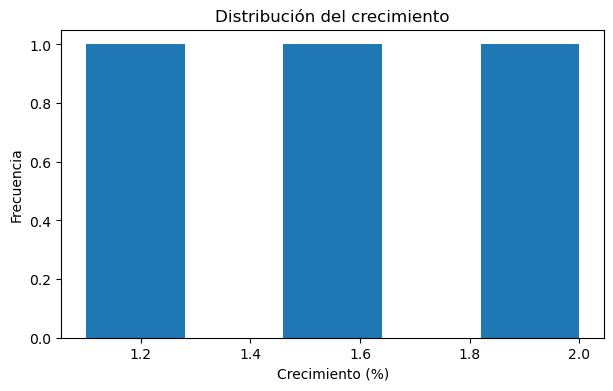

In [8]:
# HISTOGRAMA
# Usa una sola variable y muestra cómo se distribuyen sus valores.
plt.figure(figsize=(7, 4))

plt.hist(
    ejemplo['crecimiento_pct'],
    bins=5
)

plt.xlabel('Crecimiento (%)')
plt.ylabel('Frecuencia')
plt.title('Distribución del crecimiento')

plt.show()

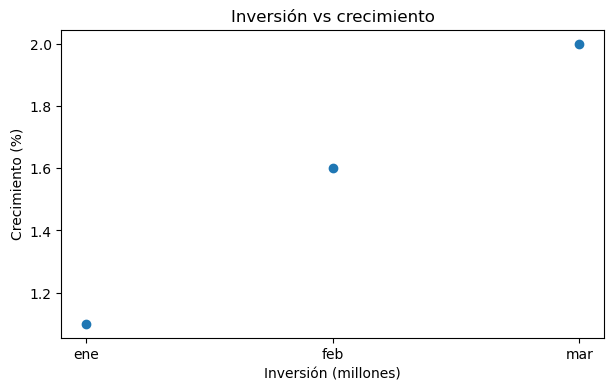

In [9]:
# SCATTER
# Usa dos variables y dibuja un punto por cada observación.
plt.figure(figsize=(7, 4))

plt.scatter(
    ejemplo['mes'],
    ejemplo['crecimiento_pct']
)

plt.xlabel('Inversión (millones)')
plt.ylabel('Crecimiento (%)')
plt.title('Inversión vs crecimiento')

plt.show()

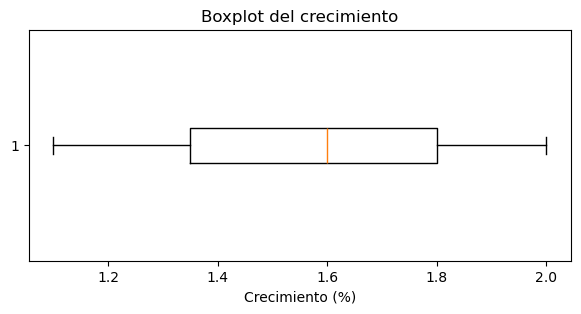

In [10]:
# BOXPLOT
# Usa una sola variable y resume su distribución,
# mostrando mediana, dispersión y posibles valores extremos.
plt.figure(figsize=(7, 3))

plt.boxplot(
    ejemplo['crecimiento_pct'],
    vert=False
)

plt.xlabel('Crecimiento (%)')
plt.title('Boxplot del crecimiento')

plt.show()

# 2. Dataset conductor de toda la clase

Durante esta clase utilizaremos el archivo:

`actividad_economica_demo.csv`

Este es un dataset **sintético y didáctico**, creado exclusivamente para aprender el flujo de trabajo de análisis de datos y Machine Learning.

> Los valores no corresponden a estadísticas oficiales del Banco Central del Ecuador, INEC u otra institución.

El objetivo no es obtener conclusiones económicas reales, sino disponer de datos que tengan una estructura parecida a un problema económico para aprender a:

- explorar un dataset;
- interpretar variables;
- detectar problemas de calidad;
- estudiar relaciones entre variables;
- construir modelos de regresión;
- medir sus errores;
- interpretar sus resultados.

---

## ¿Qué representa una fila?

Cada fila representa una observación correspondiente a una combinación de:

**mes + región + sector económico**

Por ejemplo, conceptualmente una fila podría representar:

> Sector industrial de la región Costa durante marzo de 2025.

Para esa observación disponemos de información sobre inflación, desempleo, exportaciones, inversión, precio del petróleo, confianza y crecimiento de la actividad.

Por tanto, una fila podría leerse conceptualmente así:

| Variable | Valor de ejemplo |
|---|---:|
| Fecha | marzo 2025 |
| Región | Costa |
| Sector | Industria |
| Inflación | 2.3 % |
| Desempleo | 4.8 % |
| Exportaciones | 850 millones |
| Inversión | 320 millones |
| Precio del petróleo | 72 USD |
| Índice de confianza | 64 |
| Crecimiento de actividad | 2.7 % |

Esto significaría:

> Durante ese mes, para esa región y sector, observamos determinadas condiciones económicas y un crecimiento de actividad del 2.7 %.

Nuestro objetivo será investigar si parte de ese crecimiento puede ser **predicho a partir de las demás variables**.

---

## Variables del dataset

| Columna | ¿Qué representa? | Tipo |
|---|---|---|
| `fecha` | Mes en el que se realizó la observación | fecha |
| `region` | Región geográfica a la que pertenece la observación | categórica |
| `sector` | Sector de actividad económica | categórica |
| `inflacion_pct` | Variación porcentual simulada del nivel de precios | numérica |
| `desempleo_pct` | Porcentaje simulado de desempleo | numérica |
| `exportaciones_mill` | Valor de exportaciones expresado en millones | numérica |
| `inversion_mill` | Valor de inversión expresado en millones | numérica |
| `precio_petroleo_usd` | Precio simulado del barril de petróleo en USD | numérica |
| `indice_confianza` | Indicador sintético de expectativas/confianza económica | numérica |
| `crecimiento_actividad_pct` | Crecimiento porcentual de la actividad económica que intentaremos predecir | numérica |

---

## ¿Por qué podrían relacionarse estas variables con el crecimiento?

Antes de utilizar Machine Learning necesitamos formular una hipótesis razonable sobre nuestros datos.

No estamos afirmando todavía que una variable **cause** a otra. Solamente estamos preguntándonos si podría existir una relación útil para predecir.

---

## `inversion_mill` — Inversión

Representa la cantidad simulada de inversión realizada durante el período.

Conceptualmente, una mayor inversión puede estar asociada con:

- compra de maquinaria;
- ampliación de instalaciones;
- construcción;
- contratación de personal;
- incorporación de tecnología;
- aumento de capacidad productiva.

Por eso podríamos esperar una relación como:

    mayor inversión
            ↓
    mayor capacidad productiva
            ↓
    posible mayor actividad económica

En nuestro análisis podemos preguntarnos:

> ¿Los meses con mayor inversión presentan también mayor crecimiento?

Esta será una de las primeras relaciones que estudiaremos mediante regresión lineal.

Pero debemos tener cuidado:

**que inversión y crecimiento estén relacionados no significa automáticamente que la inversión sea la causa del crecimiento.**

También podría ocurrir que las empresas inviertan más precisamente porque esperan que la economía crezca.

---

## `exportaciones_mill` — Exportaciones

Representa el valor simulado de bienes y servicios vendidos al exterior.

Un aumento de las exportaciones puede estar asociado con una mayor demanda por producción nacional.

Conceptualmente:

    mayor demanda externa
            ↓
    mayores exportaciones
            ↓
    mayor producción
            ↓
    posible mayor actividad económica

Pero esta relación puede depender mucho del sector.

Por ejemplo, el comportamiento de las exportaciones puede ser más relevante para:

- agricultura;
- pesca;
- minería;
- petróleo;
- manufactura exportadora;

que para actividades orientadas principalmente al mercado interno.

---

## `precio_petroleo_usd` — Precio del petróleo

Representa el precio simulado del barril de petróleo expresado en dólares.

En una economía exportadora de petróleo como Ecuador, esta variable puede estar relacionada con diferentes componentes de la actividad económica.

Por ejemplo:

    precio del petróleo ↑
              ↓
    valor de exportaciones petroleras ↑
              ↓
    ingresos relacionados con petróleo ↑
              ↓
    posible efecto sobre actividad económica

Sin embargo, **no todos los sectores reaccionan igual**.

Un precio elevado del petróleo también puede estar asociado con mayores costos energéticos o de transporte en determinadas actividades.

Por eso no debemos asumir antes de analizar los datos que:

    petróleo ↑ = crecimiento ↑

El modelo deberá mostrarnos qué relación aparece en el dataset.

---

## `indice_confianza` — Índice de confianza

Es una variable **sintética** que intenta representar el grado de optimismo o pesimismo de los agentes económicos.

Podemos imaginarlo como un indicador resumido de las expectativas de:

- consumidores;
- empresas;
- inversionistas.

Por ejemplo, podemos interpretar valores altos como mayor confianza y valores bajos como menor confianza.

Conceptualmente:

    mayor confianza
          ↓
    empresas más dispuestas a invertir
          ↓
    consumidores más dispuestos a gastar
          ↓
    posible aumento de actividad económica

Por ejemplo, aunque dos períodos tengan condiciones económicas similares, las decisiones pueden ser distintas si las expectativas son diferentes.

En este dataset utilizaremos el índice principalmente como una **variable predictora**.

No debemos interpretar que un punto adicional de confianza necesariamente *cause* una cantidad determinada de crecimiento.

---

## `inflacion_pct` — Inflación

Representa el aumento porcentual simulado de los precios.

La inflación puede relacionarse con la actividad de diferentes maneras.

Una inflación moderada podría aparecer durante períodos de mayor demanda, mientras que una inflación muy elevada puede:

- reducir poder adquisitivo;
- aumentar incertidumbre;
- afectar costos;
- modificar decisiones de consumo e inversión.

Por ello no debemos asumir que la relación será siempre positiva o siempre negativa.

Una de nuestras tareas será observar:

> ¿Qué relación aparece entre inflación y crecimiento dentro de este dataset?

---

## `desempleo_pct` — Desempleo

Representa el porcentaje simulado de personas desempleadas.

Podríamos esperar que períodos con menor actividad económica presenten mayor desempleo:

    actividad económica ↓
             ↓
    demanda de trabajadores ↓
             ↓
    desempleo ↑

Por eso podría aparecer una relación negativa entre desempleo y crecimiento.

Pero nuevamente estamos hablando de una **hipótesis** que debemos comprobar en los datos.

---

## `region` — Región

No es una cantidad numérica.

Representa una categoría geográfica.

Dos observaciones pueden presentar valores económicos similares pero pertenecer a regiones con estructuras productivas diferentes.

Por ejemplo, una región puede tener mayor presencia de:

- industria;
- agricultura;
- comercio;
- servicios;
- actividad exportadora.

Por ello puede resultar útil que el modelo conozca la región.

Más adelante veremos cómo convertir variables categóricas como esta en información que pueda utilizar un modelo matemático.

---

## `sector` — Sector económico

También es una variable categórica.

Permite distinguir observaciones provenientes de distintas actividades económicas.

Esto es importante porque una misma variable puede afectar de forma distinta a cada sector.

Por ejemplo, un aumento del precio del petróleo podría tener una relación diferente con:

- transporte;
- comercio;
- agricultura;
- industria;
- servicios.

Por tanto, conocer el sector puede aportar información adicional al modelo.

---

# Nuestra variable objetivo

La columna:

`crecimiento_actividad_pct`

será nuestra **variable objetivo**.

También la llamaremos:

- variable dependiente;
- `target`;
- `y`.

Es lo que queremos intentar predecir.

Las demás variables serán candidatas a convertirse en variables de entrada:

`X`

Nuestro problema puede expresarse inicialmente como:

    inflación
    desempleo
    exportaciones
    inversión
    precio petróleo
    confianza
    región
    sector
         │
         │
         ▼
      MODELO
         │
         ▼
    crecimiento
    de actividad

En Machine Learning escribiríamos conceptualmente:

    X → modelo → ŷ

donde:

- `X` contiene la información que conocemos;
- `y` contiene el crecimiento real observado;
- `ŷ` representa el crecimiento que predice nuestro modelo.

---

# Una pregunta importante antes de modelar

No asumiremos que todas estas variables son útiles.

Nuestro trabajo será descubrir:

1. qué contiene realmente el dataset;
2. qué calidad tienen los datos;
3. qué variables parecen relacionarse con el crecimiento;
4. cuáles aportan información predictiva;
5. cuáles parecen aportar poco;
6. si las relaciones son lineales o no;
7. si existen valores atípicos;
8. si el modelo generaliza a datos que no utilizó para aprender.

Por eso **no empezaremos ejecutando directamente un algoritmo de Machine Learning**.

Primero exploraremos y trataremos de entender los datos.

In [11]:
# Leemos el CSV y convertimos la fecha a datetime.
df = pd.read_csv(DATA_DIR / 'actividad_economica_demo.csv')

# head() muestra las primeras filas; no resume toda la tabla.
df.head()

,fecha,region,sector,inflacion_pct,desempleo_pct,exportaciones_mill,inversion_mill,precio_petroleo_usd,indice_confianza,crecimiento_actividad_pct,tipo_dato
0,2019-01-01,Costa,Servicios,2.33,6.75,231.63,74.86,42.80,42.42,0.10,SINTETICO_DIDACTICO
1,2019-01-01,Sierra,Comercio,2.42,6.32,268.54,106.37,43.73,44.29,-0.44,SINTETICO_DIDACTICO
2,2019-01-01,Amazonía,Servicios,2.41,5.36,269.02,84.45,43.21,48.74,0.31,SINTETICO_DIDACTICO
3,2019-01-01,Insular,Servicios,2.17,5.49,264.18,103.20,46.24,53.60,1.31,SINTETICO_DIDACTICO
4,2019-02-01,Costa,Industria,2.42,6.89,304.05,92.68,47.03,37.47,1.66,SINTETICO_DIDACTICO


## Primera pregunta: ¿los datos realmente contienen lo que creemos?

La tabla anterior describe lo que **esperamos** encontrar.

Ahora debemos comprobarlo utilizando Python.

Nunca debemos asumir que un archivo está correctamente construido únicamente porque conocemos su documentación.

Vamos a revisar:

- cuántas filas existen;
- cuántas columnas;
- sus nombres;
- los tipos de datos;
- valores faltantes;
- valores duplicados;
- rangos de las variables;
- categorías disponibles;
- posibles valores imposibles.

In [12]:
# shape devuelve (número_de_filas, número_de_columnas).
print('shape:', df.shape)

# columns muestra los nombres exactos que usaremos en el código.
print('\nColumnas:')
print(df.columns.tolist())

# dtypes muestra el tipo que Pandas asignó a cada columna.
print('\nTipos:')
print(df.dtypes)

shape: (289, 11)

Columnas:
['fecha', 'region', 'sector', 'inflacion_pct', 'desempleo_pct', 'exportaciones_mill', 'inversion_mill', 'precio_petroleo_usd', 'indice_confianza', 'crecimiento_actividad_pct', 'tipo_dato']

Tipos:
fecha                         object
region                        object
sector                        object
inflacion_pct                float64
desempleo_pct                float64
exportaciones_mill           float64
inversion_mill               float64
precio_petroleo_usd          float64
indice_confianza             float64
crecimiento_actividad_pct    float64
tipo_dato                     object
dtype: object


Si una columna numérica aparece como `object`, suele ser señal de texto, símbolos o valores problemáticos. Si una fecha queda como `object`, conviene convertirla a `datetime`.

In [13]:
df['fecha'] = pd.to_datetime(df['fecha'])
print('\nTipos:')
print(df.dtypes)

df.head()


Tipos:
fecha                        datetime64[ns]
region                               object
sector                               object
inflacion_pct                       float64
desempleo_pct                       float64
exportaciones_mill                  float64
inversion_mill                      float64
precio_petroleo_usd                 float64
indice_confianza                    float64
crecimiento_actividad_pct           float64
tipo_dato                            object
dtype: object


,fecha,region,sector,inflacion_pct,desempleo_pct,exportaciones_mill,inversion_mill,precio_petroleo_usd,indice_confianza,crecimiento_actividad_pct,tipo_dato
0,2019-01-01,Costa,Servicios,2.33,6.75,231.63,74.86,42.80,42.42,0.10,SINTETICO_DIDACTICO
1,2019-01-01,Sierra,Comercio,2.42,6.32,268.54,106.37,43.73,44.29,-0.44,SINTETICO_DIDACTICO
2,2019-01-01,Amazonía,Servicios,2.41,5.36,269.02,84.45,43.21,48.74,0.31,SINTETICO_DIDACTICO
3,2019-01-01,Insular,Servicios,2.17,5.49,264.18,103.20,46.24,53.60,1.31,SINTETICO_DIDACTICO
4,2019-02-01,Costa,Industria,2.42,6.89,304.05,92.68,47.03,37.47,1.66,SINTETICO_DIDACTICO


In [14]:
# info() combina número de filas, tipo y cantidad de valores no nulos.
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 289 entries, 0 to 288
Data columns (total 11 columns):
 #   Column                     Non-Null Count  Dtype         
---  ------                     --------------  -----         
 0   fecha                      289 non-null    datetime64[ns]
 1   region                     289 non-null    object        
 2   sector                     289 non-null    object        
 3   inflacion_pct              286 non-null    float64       
 4   desempleo_pct              289 non-null    float64       
 5   exportaciones_mill         289 non-null    float64       
 6   inversion_mill             289 non-null    float64       
 7   precio_petroleo_usd        289 non-null    float64       
 8   indice_confianza           284 non-null    float64       
 9   crecimiento_actividad_pct  289 non-null    float64       
 10  tipo_dato                  289 non-null    object        
dtypes: datetime64[ns](1), float64(7), object(3)
memory usage: 25.0+ KB


`info()` es una de las primeras herramientas que conviene ejecutar siempre. Si una columna tiene menos valores “non-null” que el total de filas, sabemos que contiene faltantes.

In [15]:
# describe() resume solo las columnas numéricas por defecto.
df.describe().T.round(2)

,count,mean,min,25%,50%,75%,max,std
fecha,289,2021-12-12 17:31:20.968858112,2019-01-01 00:00:00,2020-06-01 00:00:00,2021-12-01 00:00:00,2023-06-01 00:00:00,2024-12-01 00:00:00,NaN
inflacion_pct,286.0,1.90958,-0.68,1.2725,1.97,2.5575,4.66,0.982244
desempleo_pct,289.0,5.182803,2.86,4.58,5.18,5.84,7.99,0.943398
exportaciones_mill,289.0,370.073426,187.17,319.59,367.31,412.37,1300.0,84.361248
inversion_mill,289.0,123.546574,65.15,105.11,123.64,141.29,203.28,25.575034
precio_petroleo_usd,289.0,56.92308,29.15,49.5,56.57,64.2,83.71,10.133508
indice_confianza,284.0,44.540986,28.15,40.875,44.925,48.0125,57.07,5.317142
crecimiento_actividad_pct,289.0,1.848789,-1.27,0.98,1.82,2.75,15.0,1.535665


### Cómo leer `describe()`

- `count`: cantidad de valores no nulos;
- `mean`: promedio;
- `std`: dispersión;
- `min` y `max`: extremos;
- `25%`, `50%`, `75%`: cuartiles.

Si `max` está extremadamente lejos del 75%, podría existir un outlier. **Eso es una señal para investigar, no una orden para borrarlo.**

In [16]:
# Las categorías también deben entenderse.
print('Regiones:')
print(df['region'].value_counts())

print('\nSectores:')
print(df['sector'].value_counts())

Regiones:
region
Costa       73
Sierra      72
Amazonía    72
Insular     72
Name: count, dtype: int64

Sectores:
sector
Servicios    99
Comercio     83
Industria    73
Agro         34
Name: count, dtype: int64


`value_counts()` responde cuántas observaciones hay en cada categoría. Un grupo con muy pocas filas puede producir estimaciones inestables o resultados difíciles de generalizar.

In [17]:
# Revisamos observaciones con los mayores crecimientos.
df.nlargest(8, 'crecimiento_actividad_pct')[
    ['fecha', 'region', 'sector', 'crecimiento_actividad_pct']
]

,fecha,region,sector,crecimiento_actividad_pct
33,2019-09-01,Sierra,Comercio,15.00
251,2024-03-01,Insular,Industria,5.57
215,2023-06-01,Insular,Agro,5.02
84,2020-10-01,Costa,Servicios,4.75
219,2023-07-01,Insular,Industria,4.74
204,2023-04-01,Costa,Comercio,4.58
267,2024-07-01,Insular,Servicios,4.51
103,2021-02-01,Insular,Comercio,4.47


### ¿Por qué mirar los casos extremos?

Porque un promedio puede esconderlos. Aquí debemos preguntarnos:

- ¿son meses/sectores plausibles?
- ¿es un valor genuino o un error de captura?
- ¿podría dominar RMSE más adelante?

En este dataset insertamos intencionalmente algún valor extremo para aprender a detectarlo.

## 2.1 Calidad de datos: faltantes, duplicados y rangos

Antes de entrenar, revisamos problemas básicos. Un modelo no “arregla” automáticamente un dato incorrecto.

In [18]:
# Cantidad de valores faltantes por columna.
nulos = df.isna().sum().sort_values(ascending=False)
nulos

indice_confianza             5
inflacion_pct                3
fecha                        0
region                       0
sector                       0
desempleo_pct                0
exportaciones_mill           0
inversion_mill               0
precio_petroleo_usd          0
crecimiento_actividad_pct    0
tipo_dato                    0
dtype: int64

Un valor faltante puede tener distintos significados: “no observado”, “no aplica”, “error de carga” o “dato todavía no publicado”. La estrategia depende del significado, no solo de la técnica.

In [19]:
# duplicated() marca filas repetidas exactamente.
print('Filas duplicadas:', df.duplicated().sum())

Filas duplicadas: 1


In [20]:
df[df.duplicated(keep=False)]

,fecha,region,sector,inflacion_pct,desempleo_pct,exportaciones_mill,inversion_mill,precio_petroleo_usd,indice_confianza,crecimiento_actividad_pct,tipo_dato
20,2019-06-01,Costa,Comercio,4.07,5.29,359.1,71.28,56.25,45.1,1.56,SINTETICO_DIDACTICO
288,2019-06-01,Costa,Comercio,4.07,5.29,359.1,71.28,56.25,45.1,1.56,SINTETICO_DIDACTICO


In [21]:
# Revisamos reglas lógicas simples.
validaciones = {
    'inflacion_fuera_rango': (~df['inflacion_pct'].between(-20, 100)) & df['inflacion_pct'].notna(),
    'desempleo_fuera_rango': (~df['desempleo_pct'].between(0, 100)) & df['desempleo_pct'].notna(),
    'inversion_negativa': df['inversion_mill'] < 0,
}

for nombre, mascara in validaciones.items():
    print(nombre, int(mascara.sum()))

inflacion_fuera_rango 0
desempleo_fuera_rango 0
inversion_negativa 0


Estas reglas no son universales; son **reglas de negocio/calidad**. El punto es convertir conocimiento del dominio en comprobaciones explícitas.

## 2.2 Limpieza mínima para continuar

Para el ejercicio:

- eliminaremos duplicados exactos;
- imputaremos faltantes numéricos con la mediana;
- eliminaremos una columna que no nos aporta datos;
- eliminaremos el dato atípico (outlier).

In [22]:
# Eliminamos filas duplicadas y hacemos una copia.
df_limpio = df.drop_duplicates().copy()

# Eliminamos una columna que no aporta información al modelo.
df_limpio = df_limpio.drop(columns=['tipo_dato'])

# Eliminamos el outlier que identificamos previamente.
df_limpio = df_limpio.drop(index=33)

# Seleccionamos las columnas numéricas.
columnas_numericas = df_limpio.select_dtypes(include='number').columns

# Rellenamos valores faltantes numéricos con la mediana.
for col in columnas_numericas:
    df_limpio[col] = df_limpio[col].fillna(
        df_limpio[col].median()
    )

print('Shape original:', df.shape)
print('Shape limpio:', df_limpio.shape)
print('Nulos restantes:', df_limpio.isna().sum().sum())

Shape original: (289, 11)
Shape limpio: (287, 10)
Nulos restantes: 0


In [23]:
print('DATASET ORIGINAL')
display(df.head(10))

print('DATASET LIMPIO')
display(df_limpio.head(10))

DATASET ORIGINAL


,fecha,region,sector,inflacion_pct,desempleo_pct,exportaciones_mill,inversion_mill,precio_petroleo_usd,indice_confianza,crecimiento_actividad_pct,tipo_dato
0,2019-01-01,Costa,Servicios,2.33,6.75,231.63,74.86,42.80,42.42,0.10,SINTETICO_DIDACTICO
1,2019-01-01,Sierra,Comercio,2.42,6.32,268.54,106.37,43.73,44.29,-0.44,SINTETICO_DIDACTICO
2,2019-01-01,Amazonía,Servicios,2.41,5.36,269.02,84.45,43.21,48.74,0.31,SINTETICO_DIDACTICO
3,2019-01-01,Insular,Servicios,2.17,5.49,264.18,103.20,46.24,53.60,1.31,SINTETICO_DIDACTICO
4,2019-02-01,Costa,Industria,2.42,6.89,304.05,92.68,47.03,37.47,1.66,SINTETICO_DIDACTICO
5,2019-02-01,Sierra,Industria,1.52,5.88,286.62,113.21,53.81,48.01,1.80,SINTETICO_DIDACTICO
6,2019-02-01,Amazonía,Comercio,2.19,5.90,238.21,84.93,51.43,40.29,-0.62,SINTETICO_DIDACTICO
7,2019-02-01,Insular,Comercio,1.38,5.96,210.30,87.92,58.57,NaN,2.11,SINTETICO_DIDACTICO
8,2019-03-01,Costa,Servicios,1.92,5.61,355.58,95.85,57.97,36.91,0.26,SINTETICO_DIDACTICO
9,2019-03-01,Sierra,Comercio,2.27,6.23,273.53,93.07,56.49,45.47,0.44,SINTETICO_DIDACTICO


DATASET LIMPIO


,fecha,region,sector,inflacion_pct,desempleo_pct,exportaciones_mill,inversion_mill,precio_petroleo_usd,indice_confianza,crecimiento_actividad_pct
0,2019-01-01,Costa,Servicios,2.33,6.75,231.63,74.86,42.80,42.420,0.10
1,2019-01-01,Sierra,Comercio,2.42,6.32,268.54,106.37,43.73,44.290,-0.44
2,2019-01-01,Amazonía,Servicios,2.41,5.36,269.02,84.45,43.21,48.740,0.31
3,2019-01-01,Insular,Servicios,2.17,5.49,264.18,103.20,46.24,53.600,1.31
4,2019-02-01,Costa,Industria,2.42,6.89,304.05,92.68,47.03,37.470,1.66
5,2019-02-01,Sierra,Industria,1.52,5.88,286.62,113.21,53.81,48.010,1.80
6,2019-02-01,Amazonía,Comercio,2.19,5.90,238.21,84.93,51.43,40.290,-0.62
7,2019-02-01,Insular,Comercio,1.38,5.96,210.30,87.92,58.57,44.925,2.11
8,2019-03-01,Costa,Servicios,1.92,5.61,355.58,95.85,57.97,36.910,0.26
9,2019-03-01,Sierra,Comercio,2.27,6.23,273.53,93.07,56.49,45.470,0.44


# 3. Explorar la relación entre variables

Antes de construir una recta, veamos si existe alguna relación visible entre **inversión** y **crecimiento de actividad**.

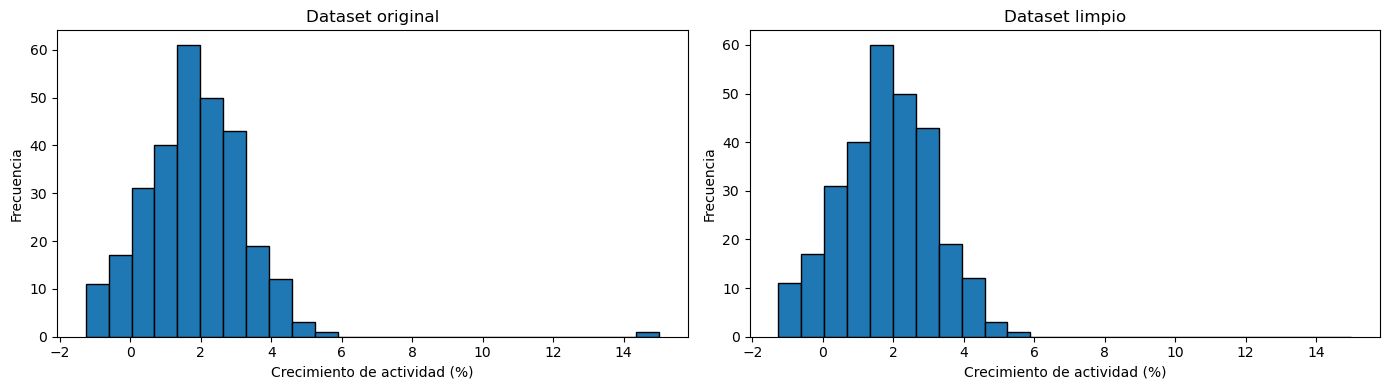

In [24]:
# Histograma: ¿cómo se distribuye la variable objetivo?
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

# Usamos los mismos intervalos para ambos histogramas.
bins = 25
rango = (
    df['crecimiento_actividad_pct'].min(),
    df['crecimiento_actividad_pct'].max()
)

# Dataset original
axes[0].hist(
    df['crecimiento_actividad_pct'],
    bins=bins,
    range=rango,
    edgecolor='black'
)

axes[0].set_xlabel('Crecimiento de actividad (%)')
axes[0].set_ylabel('Frecuencia')
axes[0].set_title('Dataset original')


# Dataset limpio
axes[1].hist(
    df_limpio['crecimiento_actividad_pct'],
    bins=bins,
    range=rango,
    edgecolor='black'
)

axes[1].set_xlabel('Crecimiento de actividad (%)')
axes[1].set_ylabel('Frecuencia')
axes[1].set_title('Dataset limpio')


plt.tight_layout()
plt.show()

El histograma permite ver centro, dispersión, asimetría y valores aislados.

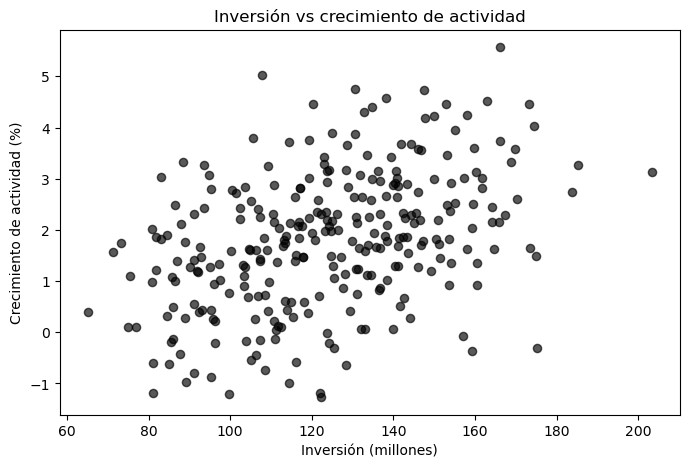

In [25]:
# Scatter: cada punto es una observación.
plt.figure(figsize=(8, 5))
plt.scatter(
    df_limpio['inversion_mill'],
    df_limpio['crecimiento_actividad_pct'],
    alpha=0.65,
    color='black',
    s=35
)
plt.xlabel('Inversión (millones)')
plt.ylabel('Crecimiento de actividad (%)')
plt.title('Inversión vs crecimiento de actividad')
plt.show()

### Qué preguntarnos al ver el scatter

- ¿la nube parece subir, bajar o no mostrar dirección?
- ¿la relación parece recta o curva?
- ¿hay grupos separados?
- ¿la dispersión aumenta a medida que X crece?
- ¿hay puntos aislados?

No necesitamos una relación perfecta para usar regresión. Lo que buscamos es saber si una **aproximación lineal** tiene sentido como baseline.

In [26]:
# Correlación de cada variable numérica con el objetivo.
correlaciones = (
    df_limpio.select_dtypes(include='number')
    .corr()['crecimiento_actividad_pct']
    .sort_values(ascending=False)
)
correlaciones

crecimiento_actividad_pct    1.000000
inversion_mill               0.407283
exportaciones_mill           0.326875
precio_petroleo_usd          0.303201
indice_confianza             0.158599
inflacion_pct               -0.169346
desempleo_pct               -0.287697
Name: crecimiento_actividad_pct, dtype: float64

### Interpretación de correlaciones

La **correlación** mide la relación lineal entre dos variables numéricas y su dirección.

En Pandas podemos calcularla con:

```python
df.corr()
```

Por defecto se utiliza la **correlación de Pearson**, cuyo valor se encuentra entre:

$$
-1 \leq r \leq 1
$$

- $r > 0$ → relación positiva: cuando una variable aumenta, la otra tiende a aumentar.
- $r < 0$ → relación negativa: cuando una aumenta, la otra tiende a disminuir.
- $r \approx 0$ → no existe una relación lineal clara.

#### Intensidad aproximada

| $|r|$ | Interpretación |
|---:|---|
| 0.00 – 0.19 | muy débil |
| 0.20 – 0.39 | débil |
| 0.40 – 0.59 | moderada |
| 0.60 – 0.79 | fuerte |
| 0.80 – 1.00 | muy fuerte |

El **signo** indica la dirección y el valor absoluto $|r|$ indica la intensidad.

---

#### Resultados de nuestro dataset

| Variable | Correlación |
|---|---:|
| `inversion_mill` | 0.407 |
| `exportaciones_mill` | 0.327 |
| `precio_petroleo_usd` | 0.303 |
| `indice_confianza` | 0.159 |
| `inflacion_pct` | -0.169 |
| `desempleo_pct` | -0.288 |

##### Interpretación

- **Inversión: 0.407** → relación positiva moderada. A mayor inversión, el crecimiento tiende a ser mayor.
- **Exportaciones: 0.327** → relación positiva débil.
- **Precio del petróleo: 0.303** → relación positiva débil.
- **Índice de confianza: 0.159** → relación positiva muy débil.
- **Inflación: -0.169** → relación negativa muy débil.
- **Desempleo: -0.288** → relación negativa débil.

La inversión presenta la mayor relación lineal individual con nuestro objetivo, por lo que será una buena variable para comenzar una **regresión lineal simple**:

```text
X = inversion_mill
y = crecimiento_actividad_pct
```

> **Correlación no significa causalidad.** Una relación entre dos variables no demuestra que una sea la causa de la otra.

Además, Pearson mide principalmente **relaciones lineales**, por lo que una correlación pequeña no significa necesariamente que no exista ninguna relación.

---

### ¿Qué ocurre con las variables categóricas?

Variables como:

- `region`
- `sector`

no son numéricas, por lo que no pueden incluirse directamente en `corr()`.

Podemos convertirlas mediante **One-Hot Encoding**.

Por ejemplo:

```text
region = Costa
```

se transforma en:

```text
region_Costa   region_Sierra   region_Insular
     1               0               0
```

Esto permite explorar si determinadas regiones o sectores están asociados con valores mayores o menores de crecimiento.

Sin embargo, una correlación de una columna binaria debe interpretarse como una **comparación de esa categoría frente al resto**, no como una relación continua como ocurre con inversión o desempleo.

In [27]:
df_codificado = pd.get_dummies(
    df_limpio,
    columns=['region', 'sector'],
    dtype=int
)
display(df_codificado.head())

correlaciones = (
    df_codificado
    .select_dtypes(include='number')
    .corr()['crecimiento_actividad_pct']
    .drop('crecimiento_actividad_pct')
    .sort_values(ascending=False)
)
display(correlaciones)

,fecha,inflacion_pct,desempleo_pct,exportaciones_mill,inversion_mill,precio_petroleo_usd,indice_confianza,crecimiento_actividad_pct,region_Amazonía,region_Costa,region_Insular,region_Sierra,sector_Agro,sector_Comercio,sector_Industria,sector_Servicios
0,2019-01-01,2.33,6.75,231.63,74.86,42.80,42.42,0.10,0,1,0,0,0,0,0,1
1,2019-01-01,2.42,6.32,268.54,106.37,43.73,44.29,-0.44,0,0,0,1,0,1,0,0
2,2019-01-01,2.41,5.36,269.02,84.45,43.21,48.74,0.31,1,0,0,0,0,0,0,1
3,2019-01-01,2.17,5.49,264.18,103.20,46.24,53.60,1.31,0,0,1,0,0,0,0,1
4,2019-02-01,2.42,6.89,304.05,92.68,47.03,37.47,1.66,0,1,0,0,0,0,1,0


inversion_mill         0.407283
exportaciones_mill     0.326875
precio_petroleo_usd    0.303201
region_Insular         0.202588
indice_confianza       0.158599
sector_Industria       0.157094
region_Costa           0.069302
sector_Servicios      -0.022882
sector_Comercio       -0.060088
sector_Agro           -0.094357
region_Sierra         -0.134410
region_Amazonía       -0.138107
inflacion_pct         -0.169346
desempleo_pct         -0.287697
Name: crecimiento_actividad_pct, dtype: float64

# 4. Regresión lineal simple: construir una recta

La **regresión lineal simple** es un modelo estadístico y de Machine Learning que intenta describir y predecir la relación entre **una sola variable de entrada** y **una variable objetivo numérica**.

La idea es encontrar la **línea recta que mejor se ajuste a los datos**.

---

## ¿Qué queremos hacer?

Supongamos que queremos estudiar si existe relación entre:

- **X = inversión en millones de dólares**
- **y = crecimiento de la actividad económica (%)**

Tenemos observaciones históricas como estas:

| Inversión (X) | Crecimiento (y) |
|---:|---:|
| 100 | 1.2 |
| 120 | 1.8 |
| 140 | 2.1 |
| 160 | 2.7 |
| 180 | 3.0 |

Visualmente podríamos observar que, en general, cuando la inversión aumenta, el crecimiento también parece aumentar.

La regresión lineal intenta representar esa relación mediante una línea.

<p align="center">
    <img src="../material_apoyo/regresion_lineal.png" width="650">
</p>

---

## La fórmula de una regresión lineal simple

<p align="center">
    <img src="../material_apoyo/funcion_lineal.png" width="350">
</p>

Una recta se puede expresar como:

$$
y = b + mX
$$

En regresión lineal usamos:

$$
\hat{y} = b_0 + b_1X
$$

donde:

- $b_0$ es el **intercepto**: valor predicho de $y$ cuando $X=0$.
- $b_1$ es la **pendiente**: cuánto cambia $\hat y$ cuando $X$ aumenta una unidad.
- $X$ es la variable de entrada.
- $\hat y$ es el valor predicho por el modelo.

En el gráfico:

$$
m=\frac{q}{p}
$$

representa la pendiente, por lo que:

$$
m=b_1
$$

y el punto:

$$
(0,b)
$$

corresponde al intercepto:

$$
b=b_0
$$

Si $X=0$ está muy lejos de los valores reales observados, el intercepto sigue siendo necesario matemáticamente, pero puede no tener una interpretación práctica útil.

El modelo aprende automáticamente los valores de $b_0$ y $b_1$ que mejor ajustan la recta a los datos.


In [28]:
# Usamos exactamente las mismas 5 observaciones del ejemplo manual.
# Así podremos comprobar que el cálculo a mano y scikit-learn producen la misma recta.
manual = pd.DataFrame({
    'inversion_mill': [100, 120, 140, 160, 180],
    'crecimiento_actividad_pct': [1.2, 1.8, 2.1, 2.7, 3.0]
})

manual


,inversion_mill,crecimiento_actividad_pct
0,100,1.2
1,120,1.8
2,140,2.1
3,160,2.7
4,180,3.0



## 4.1 Probar rectas candidatas

Antes de “dejar que sklearn calcule”, imaginemos tres rectas distintas. No pretendemos que sus números sean óptimos; queremos ver que **cambiar intercepto y pendiente cambia las predicciones y el error**.

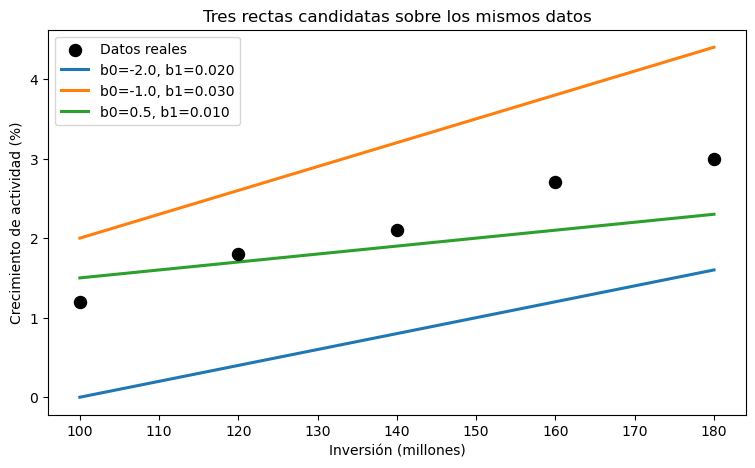

In [29]:
x = manual['inversion_mill'].to_numpy()
y = manual['crecimiento_actividad_pct'].to_numpy()

# Tres candidatos definidos a propósito con comportamientos distintos.
# Los puntos reales se dibujan en NEGRO para no confundirse con ninguna línea.
candidatos = [
    (-2.0, 0.020, 'tab:blue'),
    (-1.0, 0.030, 'tab:orange'),
    ( 0.5, 0.010, 'tab:green')
]

plt.figure(figsize=(9, 5))
plt.scatter(x, y, s=75, color='black', label='Datos reales', zorder=5)

x_ordenado = np.sort(x)
for b0, b1, color in candidatos:
    pred_linea = b0 + b1 * x_ordenado
    plt.plot(x_ordenado, pred_linea, linewidth=2.2, color=color,
             label=f'b0={b0:.1f}, b1={b1:.3f}')

plt.xlabel('Inversión (millones)')
plt.ylabel('Crecimiento de actividad (%)')
plt.title('Tres rectas candidatas sobre los mismos datos')
plt.legend()
plt.show()

## ¿Qué es SSE y cómo se calcula?

`SSE` significa **Sum of Squared Errors**, es decir:

> **Suma de los errores al cuadrado**

Sirve para medir qué tan alejadas están las predicciones de los valores reales.

La fórmula es:

$$
SSE = \sum_{i=1}^{n}(y_i-\hat{y}_i)^2
$$

donde:

- $y_i$ = valor real;
- $\hat{y}_i$ = valor predicho;
- $y_i-\hat{y}_i$ = error o residuo.

### Ejemplo manual

Supongamos que tenemos:

| $y$ real | $\hat y$ predicho | Error $y-\hat y$ | Error al cuadrado |
|---:|---:|---:|---:|
| 1.2 | 1.3 | -0.1 | 0.01 |
| 1.8 | 1.7 | 0.1 | 0.01 |
| 2.1 | 2.4 | -0.3 | 0.09 |

Primero calculamos los errores:

$$
1.2-1.3=-0.1
$$

$$
1.8-1.7=0.1
$$

$$
2.1-2.4=-0.3
$$

Luego elevamos cada error al cuadrado:

$$
(-0.1)^2=0.01
$$

$$
(0.1)^2=0.01
$$

$$
(-0.3)^2=0.09
$$

Finalmente sumamos:

$$
SSE=0.01+0.01+0.09
$$

$$
\boxed{SSE=0.11}
$$

### ¿Cómo se interpreta?

Cuanto menor sea el SSE, más cerca están, en conjunto, las predicciones de los valores reales.

Por ejemplo:

- Recta A: $SSE=0.11$
- Recta B: $SSE=0.45$
- Recta C: $SSE=1.20$

La recta A sería la que mejor se ajusta a esos datos.

### ¿Por qué elevamos los errores al cuadrado?

Si simplemente sumáramos los errores:

$$
2+(-2)=0
$$

parecería que no existe error.

Al elevarlos al cuadrado:

$$
2^2+(-2)^2=4+4=8
$$

todos los errores aportan positivamente.

Además, los errores grandes reciben una penalización mayor.

> La regresión lineal por mínimos cuadrados busca los valores de $b_0$ y $b_1$ que hagan que el SSE sea lo más pequeño posible.

Menor SSE significa que, en conjunto, la recta quedó más cerca de los puntos según el criterio cuadrático. La regresión de mínimos cuadrados busca los $b_0$ y $b_1$ que minimizan este valor.

## 4.2 ¿De dónde salen la pendiente y el intercepto?

Para una regresión lineal simple tenemos:

$$
\hat{y} = b_0 + b_1X
$$

donde:

- $b_1$ es la pendiente;
- $b_0$ es el intercepto.

La pendiente se calcula como:

$$
b_1 =
\frac{
\sum (x_i-\bar{x})(y_i-\bar{y})
}{
\sum (x_i-\bar{x})^2
}
$$

y luego el intercepto:

$$
b_0 = \bar{y} - b_1\bar{x}
$$

Usaremos los siguientes datos:

| Inversión $X$ | Crecimiento $y$ |
|---:|---:|
| 100 | 1.2 |
| 120 | 1.8 |
| 140 | 2.1 |
| 160 | 2.7 |
| 180 | 3.0 |

---

### Paso 1. Calcular las medias

La media de $X$ es:

$$
\bar{x}
=
\frac{100+120+140+160+180}{5}
$$

$$
\bar{x}
=
\frac{700}{5}
=
140
$$

La media de $y$ es:

$$
\bar{y}
=
\frac{1.2+1.8+2.1+2.7+3.0}{5}
$$

$$
\bar{y}
=
\frac{10.8}{5}
=
2.16
$$

Por tanto:

$$
\bar{x}=140
$$

$$
\bar{y}=2.16
$$

---

### Paso 2. Calcular las diferencias respecto a las medias

| $x_i$ | $y_i$ | $x_i-\bar{x}$ | $y_i-\bar{y}$ | $(x_i-\bar{x})(y_i-\bar{y})$ | $(x_i-\bar{x})^2$ |
|---:|---:|---:|---:|---:|---:|
| 100 | 1.2 | -40 | -0.96 | 38.4 | 1600 |
| 120 | 1.8 | -20 | -0.36 | 7.2 | 400 |
| 140 | 2.1 | 0 | -0.06 | 0 | 0 |
| 160 | 2.7 | 20 | 0.54 | 10.8 | 400 |
| 180 | 3.0 | 40 | 0.84 | 33.6 | 1600 |

Sumamos las dos últimas columnas:

$$
\sum (x_i-\bar{x})(y_i-\bar{y})
=
38.4+7.2+0+10.8+33.6
$$

$$
=90
$$

y:

$$
\sum (x_i-\bar{x})^2
=
1600+400+0+400+1600
$$

$$
=4000
$$

---

### Paso 3. Calcular la pendiente

Sustituimos en la fórmula:

$$
b_1=
\frac{90}{4000}
$$

$$
\boxed{b_1=0.0225}
$$

Esto significa que, según esta recta:

> por cada millón adicional de inversión, el crecimiento predicho aumenta aproximadamente **0.0225 puntos porcentuales**.

Por ejemplo, si la inversión aumenta en 10 millones:

$$
0.0225 \times 10 = 0.225
$$

el crecimiento predicho aumentaría aproximadamente:

$$
0.225
$$

puntos porcentuales.

---

### Paso 4. Calcular el intercepto

Ahora usamos:

$$
b_0=\bar{y}-b_1\bar{x}
$$

Sustituimos:

$$
b_0
=
2.16-(0.0225)(140)
$$

$$
b_0
=
2.16-3.15
$$

$$
\boxed{b_0=-0.99}
$$

---

### Paso 5. Construir la ecuación de la recta

Ya conocemos:

$$
b_0=-0.99
$$

y:

$$
b_1=0.0225
$$

Por tanto, nuestra regresión lineal es:

$$
\boxed{
\hat{y}=-0.99+0.0225X
}
$$

Por ejemplo, para una inversión de 160 millones:

$$
\hat{y}
=
-0.99+0.0225(160)
$$

$$
\hat{y}
=
-0.99+3.6
$$

$$
\boxed{\hat{y}=2.61}
$$

El valor real era:

$$
y=2.7
$$

por lo que el residuo sería:

$$
e=y-\hat{y}
$$

$$
e=2.7-2.61
$$

$$
\boxed{e=0.09}
$$

---

### ¿Qué significa la fórmula de la pendiente?

La expresión:

$$
(x_i-\bar{x})(y_i-\bar{y})
$$

nos ayuda a comprobar si $X$ e $y$ se mueven en la misma dirección.

Por ejemplo:

- si $X$ está por encima de su media y $y$ también, el producto es positivo;
- si $X$ está por debajo de su media y $y$ también, el producto también es positivo;
- si una está por encima y la otra por debajo, el producto es negativo.

Por eso, cuando valores altos de $X$ suelen coincidir con valores altos de $y$, obtenemos una pendiente positiva.

En nuestro ejemplo:

$$
b_1=0.0225>0
$$

por lo que la relación estimada entre inversión y crecimiento es positiva.

### Interpretar el coeficiente $b_1$

Si $b_1=0.02$, el modelo dice que **por cada millón adicional de inversión**, la predicción de crecimiento aumenta aproximadamente 0.02 puntos porcentuales, manteniendo el resto fuera del problema porque todavía solo tenemos una X.

Es una **asociación del modelo**, no una prueba de que aumentar inversión cause exactamente ese cambio.

### Interpretar el intercepto $b_0$

El intercepto es la predicción matemática cuando $x=0$:

$$
\hat{y}(0)=b_0
$$

Pero eso **no garantiza que tenga interpretación económica**. Si en los datos la inversión observada está entre 60 y 180 millones, `x=0` queda muy lejos del rango usado para aprender. En ese caso el intercepto es principalmente una pieza necesaria para posicionar la recta.

#### ¿Debemos forzar `b0 = 0` si X=0 “no existe”?

No automáticamente. Quitar el intercepto obliga a que la recta pase por el origen y puede empeorar mucho el ajuste. Solo tendría sentido si existe una razón teórica fuerte para afirmar que **cuando todas las X son 0, y debe ser exactamente 0** y ese origen es significativo en el problema.

## 4.3 La misma recta con `LinearRegression`

`scikit-learn` hace el mismo tipo de ajuste, pero usa álgebra lineal preparada para trabajar con muchas filas y muchas variables.

Intercepto sklearn: -0.99
Coeficiente sklearn: 0.0225


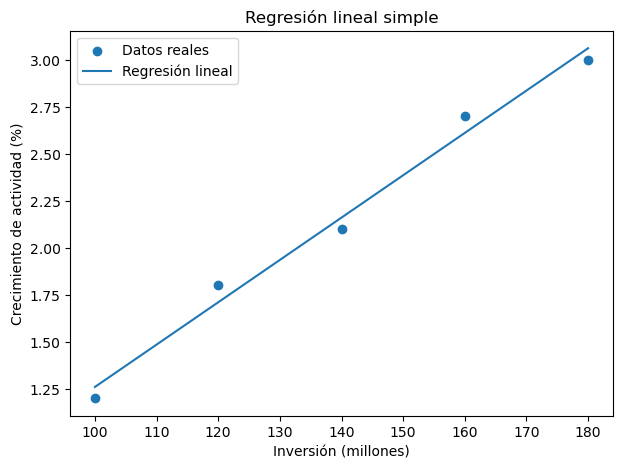

In [30]:
# Scikit-learn espera X en forma de matriz 2D: (filas, variables).
X_manual = manual[['inversion_mill']]
y_manual = manual['crecimiento_actividad_pct']

modelo_manual = LinearRegression()
modelo_manual.fit(X_manual, y_manual)

print('Intercepto sklearn:', round(modelo_manual.intercept_, 5))
print('Coeficiente sklearn:', round(modelo_manual.coef_[0], 5))

# Calculamos las predicciones para los mismos valores de inversión.
y_pred_manual = modelo_manual.predict(X_manual)

# Dibujamos los datos reales.
plt.figure(figsize=(7, 5))

plt.scatter(
    X_manual['inversion_mill'],
    y_manual,
    label='Datos reales'
)

# Dibujamos la recta aprendida por el modelo.
plt.plot(
    X_manual['inversion_mill'],
    y_pred_manual,
    label='Regresión lineal'
)

plt.xlabel('Inversión (millones)')
plt.ylabel('Crecimiento de actividad (%)')
plt.title('Regresión lineal simple')

plt.legend()
plt.show()

# 5. Métricas de regresión: cada una responde una pregunta distinta

No existe una única métrica que resuma todo. Usaremos:

| Métrica | Fórmula conceptual | Pregunta | Ideal |
|---|---|---|---:|
| **MAE** | $\frac{1}{n}\sum |y-\hat y|$ | ¿Cuánto me equivoco normalmente en unidades originales? | 0 |
| **MSE** | $\frac{1}{n}\sum (y-\hat y)^2$ | ¿Cuál es el error cuadrático medio? | 0 |
| **RMSE** | $\sqrt{MSE}$ | ¿Qué tan fuertes son los errores grandes, de nuevo en unidades originales? | 0 |
| **Bias** | $\frac{1}{n}\sum(\hat y-y)$ | ¿Tiendo sistemáticamente a predecir de más o de menos? | 0 |
| **R²** | $1-\frac{SSE_{modelo}}{SST_{media}}$ | ¿Cuánto reduce el modelo el error cuadrático respecto a predecir siempre la media? | 1 |

### Puntos importantes

- **MSE** queda en unidades al cuadrado, por eso suele ser menos intuitivo para comunicar.
- **RMSE** castiga especialmente errores grandes.
- **Bias cercano a 0 no significa modelo bueno**: errores positivos y negativos pueden cancelarse.
- **R² no es accuracy** y puede ser negativo en datos no vistos si el modelo es peor que el baseline de la media.

In [31]:
# El modelo calcula una predicción para cada valor de X.
pred = modelo_manual.predict(X_manual)

# MAE:
# promedio de las diferencias absolutas entre el valor real y el predicho.
mae = mean_absolute_error(y_manual, pred)

# MSE:
# promedio de los errores elevados al cuadrado.
mse = mean_squared_error(y_manual, pred)

# RMSE:
# raíz cuadrada del MSE.
# Vuelve a expresar el error en las mismas unidades de y.
rmse = np.sqrt(mse)

# Bias:
# promedio de (predicción - valor real).
# Positivo = tendencia a sobreestimar.
# Negativo = tendencia a subestimar.
bias = np.mean(pred - y_manual.to_numpy())

# R²:
# compara el modelo contra una referencia que siempre predice
# la media de y.
r2 = r2_score(y_manual, pred)

# Mostramos todas las métricas juntas.
pd.DataFrame({
    'metrica': ['MAE', 'MSE', 'RMSE', 'Bias', 'R2'],
    'valor': [mae, mse, rmse, bias, r2]
}).round(4)

,metrica,valor
0,MAE,0.0720
1,MSE,0.0054
2,RMSE,0.0735
3,Bias,0.0000
4,R2,0.9868


### No memorices el número: interprétalo

Si MAE = 1.2, significa que el error absoluto medio es 1.2 **puntos porcentuales de crecimiento**, porque esa es la unidad de y. Si RMSE es bastante mayor que MAE, algunos errores grandes están pesando mucho.

### Evaluación rápida del primer modelo

Nuestro modelo obtuvo:

- **MAE = 1.10** → se equivoca en promedio alrededor de **1.1 puntos porcentuales**.
- **MSE = 1.45** → promedio de los errores al cuadrado. Penaliza especialmente los errores grandes; cuanto menor, mejor.
- **RMSE = 1.20** → error típico aproximado de **1.2 puntos porcentuales**.
- **Bias ≈ 0** → no presenta una tendencia general a sobreestimar o subestimar.
- **R² = 0.126** → la inversión explica aproximadamente **12.6 % de la variabilidad del crecimiento**.

### ¿Cómo está nuestro primer modelo?

La inversión sí aporta información, pero por sí sola explica una parte pequeña del comportamiento del crecimiento.

Además, estas métricas se calcularon utilizando los mismos datos con los que entrenamos el modelo.

El siguiente paso será separar los datos en:

**Train → Validation → Test**

para comprobar si el modelo funciona también con datos que no utilizó durante su entrenamiento.

# 6. Train, Validation y Test

Hasta ahora ajustamos y medimos sobre los mismos pocos datos para comprender la mecánica. **Eso no sirve para estimar generalización.**

Eso es útil para aprender cómo funciona la regresión, pero **no nos permite saber si el modelo funcionará bien con datos nuevos**.


Una división didáctica común es:

$$
70\%\;Train \quad 15\%\;Validation \quad 15\%\;Test
$$

---

## Train

El conjunto de **Train** se utiliza para entrenar el modelo.

Aquí el algoritmo aprende sus parámetros, por ejemplo:

$$
b_0
\qquad\text{y}\qquad
b_1
$$

en una regresión lineal.

Podemos pensar en Train como:

> Los datos con los que el modelo estudia.

---

## Validation

El conjunto de **Validation** no se utiliza para aprender directamente los parámetros del modelo.

Se utiliza para que **nosotros tomemos decisiones**.

Por ejemplo:

- elegir qué variables utilizar;
- comparar regresión simple vs múltiple;
- probar transformaciones;
- elegir hiperparámetros;
- comparar diferentes modelos.

Podemos pensar en Validation como:

> Un examen de práctica que podemos revisar varias veces para mejorar nuestras decisiones.

Si un modelo funciona mal en Validation, podemos modificarlo y volver a probar.

---

## Test

El conjunto de **Test** se reserva para el final.

Se utiliza cuando ya hemos decidido:

- qué variables utilizar;
- qué transformación aplicar;
- qué modelo usar;
- qué hiperparámetros utilizar.

Podemos pensar en Test como:

> El examen final.

Su objetivo es responder:

**¿Cómo funciona el modelo con datos que nunca utilizamos para entrenarlo ni para tomar decisiones?**

Por eso debemos intentar mirar Test solamente cuando el diseño del modelo ya está cerrado.

---

## Diferencia clave entre Validation y Test

| Conjunto | ¿Para qué sirve? | ¿Podemos usarlo varias veces? |
|---|---|---|
| Train | Aprender los parámetros del modelo | Sí |
| Validation | Elegir y mejorar el modelo | Sí |
| Test | Evaluación final | Idealmente no |

La diferencia fundamental es:

> **Validation forma parte del proceso de construcción del modelo.**

> **Test sirve para evaluar el resultado final de ese proceso.**

---

In [32]:
# X e y del problema simple, ahora usando todas las filas limpias.
X = df_limpio[['inversion_mill']]
y = df_limpio['crecimiento_actividad_pct']

# Primero separamos 70% Train y 30% temporal para Val+Test.
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, random_state=42
)

# Dividimos ese 30% por la mitad -> 15% Validation y 15% Test.
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, random_state=42
)

print('Train:', X_train.shape, y_train.shape)
print('Validation:', X_val.shape, y_val.shape)
print('Test:', X_test.shape, y_test.shape)

Train: (200, 1) (200,)
Validation: (43, 1) (43,)
Test: (44, 1) (44,)


In [33]:
# Baseline: una referencia sencilla que siempre predice la media de Train.
# Sirve para saber si nuestros modelos realmente mejoran frente a una estrategia mínima.
media_train = y_train.mean()

pred_baseline_val = np.full(
    len(y_val),
    media_train
)

print('Media utilizada por el baseline:', round(media_train, 3))


Media utilizada por el baseline: 1.897


# 7. Regresión simple con todo el dataset

Ahora repetimos el mismo concepto X=`inversion_mill`, y=`crecimiento_actividad_pct`, pero respetando Train/Validation.

In [34]:
modelo_simple = LinearRegression()

# fit() aprende b0 y b1 usando SOLO Train.
modelo_simple.fit(X_train, y_train)

# predict() usa esos parámetros fijos para generar predicciones nuevas.
pred_train = modelo_simple.predict(X_train)
pred_val = modelo_simple.predict(X_val)

print('Intercepto:', round(modelo_simple.intercept_, 4))
print('Coeficiente de inversión:', round(modelo_simple.coef_[0], 5))

Intercepto: -0.6629
Coeficiente de inversión: 0.02064


El coeficiente tiene la misma interpretación que antes, pero ahora fue estimado con muchas observaciones. Aun así, no asumimos que sea causal.

In [35]:
# Comparamos desempeño dentro y fuera de Train.
def metricas_regresion(y_real, y_pred):
    return {
        'MAE': mean_absolute_error(y_real, y_pred),
        'RMSE': np.sqrt(mean_squared_error(y_real, y_pred)),
        'R2': r2_score(y_real, y_pred),
        'Bias': np.mean(np.asarray(y_pred) - np.asarray(y_real))
    }

pd.DataFrame({
    'Train': metricas_regresion(y_train, pred_train),
    'Validation': metricas_regresion(y_val, pred_val)
}).T.round(3)

,MAE,RMSE,R2,Bias
Train,0.947,1.220,0.165,0.000
Validation,1.115,1.305,0.012,0.262


### ¿Qué nos dicen Train y Validation?

- **MAE:** pasa de `0.947` a `1.115`. El error aumenta con datos que el modelo no utilizó para entrenarse.
- **RMSE:** pasa de `1.220` a `1.305`. También empeora ligeramente en Validation.
- **R²:** baja de `0.165` a `0.012`. En Train la inversión explica aproximadamente el **16.5 %** de la variabilidad, pero en Validation apenas alrededor del **1.2 %**.
- **Bias:** pasa de `0` a `0.262`. En Validation el modelo presenta una ligera tendencia a **sobreestimar** el crecimiento.

### Conclusión

El modelo no parece estar memorizando fuertemente los datos, porque los errores de Train y Validation no son extremadamente diferentes.

El principal problema es otro: **la regresión simple con inversión tiene poca capacidad predictiva**, especialmente sobre datos nuevos.

Esto sugiere que necesitaremos incorporar más información al modelo.

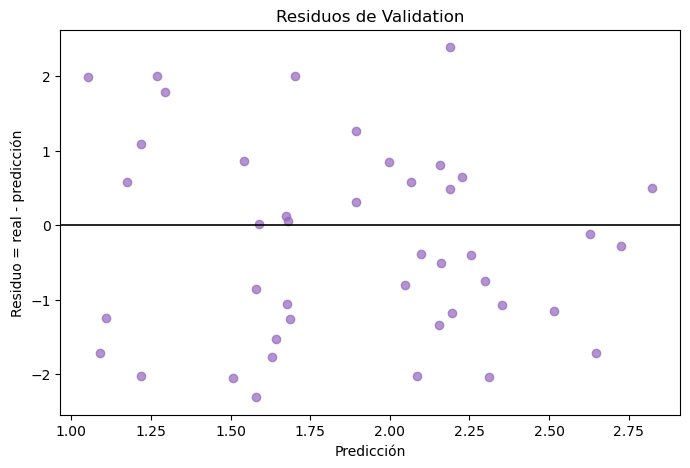

In [36]:
# Residuos en Validation = real - predicción.
residuos_val = y_val.to_numpy() - pred_val

plt.figure(figsize=(8, 5))
plt.scatter(pred_val, residuos_val, alpha=0.7, color='tab:purple')
plt.axhline(0, color='black', linewidth=1.2)
plt.xlabel('Predicción')
plt.ylabel('Residuo = real - predicción')
plt.title('Residuos de Validation')
plt.show()

### Interpretación del gráfico de residuos

En este gráfico:

- el eje X muestra las predicciones del modelo;
- el eje Y muestra el residuo:

$$
residuo = y - \hat y
$$

La línea horizontal en cero representa una predicción sin error.

- residuo positivo → el valor real fue mayor que la predicción;
- residuo negativo → el valor real fue menor que la predicción;
- residuo cercano a cero → la predicción fue bastante cercana al valor real.

### ¿Qué observamos?

Los residuos aparecen distribuidos tanto por encima como por debajo de cero.

No se observa una curva muy clara ni un patrón evidente, por lo que no parece haber una relación no lineal muy fuerte que el modelo esté ignorando.

Sin embargo, los residuos tienen una dispersión considerable: varios errores están alrededor de ±2 puntos porcentuales.

Esto coincide con las métricas anteriores: la regresión simple con inversión no está prediciendo con mucha precisión.

### ¿Qué sería ideal?

En un buen modelo esperaríamos residuos:

- distribuidos aleatoriamente alrededor de cero;
- sin formar curvas o patrones;
- con una dispersión relativamente pequeña y similar a lo largo de todo el eje X.

# 8. Regresión múltiple: primero verla en 3D

Con dos variables explicativas:

- $x_1$ = inversión;
- $x_2$ = precio del petróleo;
- $y$ = crecimiento.

La ecuación es:

$$
\hat y=b_0+b_1x_1+b_2x_2
$$

Geométricamente ya no aprendemos una línea, sino un **plano** en tres dimensiones.

In [37]:
# Seleccionamos dos X para poder visualizar el modelo como plano 3D.
X_2 = df_limpio[['inversion_mill', 'precio_petroleo_usd']]
y_2 = df_limpio['crecimiento_actividad_pct']

modelo_2 = LinearRegression().fit(X_2, y_2)

print('Intercepto:', round(modelo_2.intercept_, 4))
print('Coeficientes:')
print(pd.Series(modelo_2.coef_, index=X_2.columns).round(5))

Intercepto: -2.2421
Coeficientes:
inversion_mill         0.01886
precio_petroleo_usd    0.03005
dtype: float64


Cada coeficiente se interpreta **manteniendo constante la otra X**. Esa frase es fundamental en regresión múltiple.

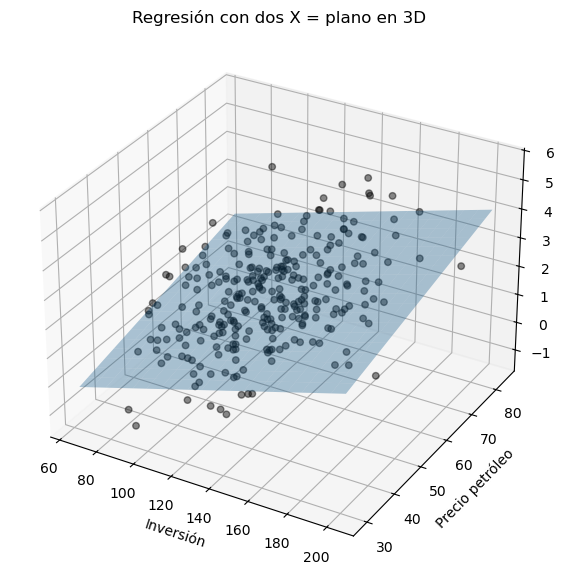

In [38]:
# Visualización 3D: puntos reales + plano predicho.
fig = plt.figure(figsize=(10, 7))
ax = fig.add_subplot(111, projection='3d')

# Puntos reales.
ax.scatter(
    X_2['inversion_mill'],
    X_2['precio_petroleo_usd'],
    y_2,
    color='black', alpha=0.45, s=22, label='Datos reales'
)

# Malla sobre el rango observado.
x1_grid = np.linspace(X_2['inversion_mill'].min(), X_2['inversion_mill'].max(), 20)
x2_grid = np.linspace(X_2['precio_petroleo_usd'].min(), X_2['precio_petroleo_usd'].max(), 20)
X1_mesh, X2_mesh = np.meshgrid(x1_grid, x2_grid)

# Predicción del plano para cada punto de la malla.
plano = (
    modelo_2.intercept_
    + modelo_2.coef_[0] * X1_mesh
    + modelo_2.coef_[1] * X2_mesh
)

ax.plot_surface(X1_mesh, X2_mesh, plano, alpha=0.35, color='tab:blue')
ax.set_xlabel('Inversión')
ax.set_ylabel('Precio petróleo')
ax.set_zlabel('Crecimiento')
ax.set_title('Regresión con dos X = plano en 3D')
plt.show()

### ¿Qué pasa con 3, 4 o 10 variables?

La fórmula continúa siendo:

$$
\hat y=b_0+b_1x_1+b_2x_2+\dots+b_px_p
$$

Pero ya no podemos dibujar ese espacio. Matemáticamente se habla de un **hiperplano**. La lógica no cambia: cada variable añade una dimensión y el modelo aprende un coeficiente para cada columna.

## 8.1 Modelo con varias variables numéricas

In [39]:
features_num = [
    'inversion_mill',
    'precio_petroleo_usd',
    'exportaciones_mill',
    'indice_confianza',
    'inflacion_pct',
    'desempleo_pct'
]

X_multi = df_limpio[features_num]
y_multi = df_limpio['crecimiento_actividad_pct']

# Mismo esquema 70/15/15.
X_train_m, X_temp_m, y_train_m, y_temp_m = train_test_split(
    X_multi, y_multi, test_size=0.30, random_state=42
)
X_val_m, X_test_m, y_val_m, y_test_m = train_test_split(
    X_temp_m, y_temp_m, test_size=0.50, random_state=42
)

modelo_multi = LinearRegression().fit(X_train_m, y_train_m)
pred_multi_val = modelo_multi.predict(X_val_m)

pd.Series(modelo_multi.coef_, index=features_num).sort_values(key=np.abs, ascending=False)

inflacion_pct         -0.163139
desempleo_pct         -0.157197
precio_petroleo_usd    0.023766
inversion_mill         0.014917
indice_confianza       0.003891
exportaciones_mill     0.001435
dtype: float64

### Cuidado al comparar magnitudes de coeficientes

`exportaciones_mill` puede estar medida en cientos y `inflacion_pct` en unidades pequeñas. Por eso un coeficiente numéricamente pequeño no significa automáticamente “variable menos importante”. Las escalas son distintas.

Más adelante veremos coeficientes estandarizados, regularización y permutation importance.

In [40]:
# Tabla de comparación simple vs múltiple en Validation.
comparacion_modelos = pd.DataFrame([
    {'modelo': 'Baseline media', **metricas_regresion(y_val, pred_baseline_val)},
    {'modelo': 'Lineal simple: inversión', **metricas_regresion(y_val, pred_val)},
    {'modelo': 'Lineal múltiple numérica', **metricas_regresion(y_val_m, pred_multi_val)}
])
comparacion_modelos.round(3)

,modelo,MAE,RMSE,R2,Bias
0,Baseline media,1.106,1.343,-0.045,0.279
1,Lineal simple: inversión,1.115,1.305,0.012,0.262
2,Lineal múltiple numérica,1.034,1.198,0.168,0.353


La pregunta no es “¿el modelo múltiple tiene más variables?”, sino **“¿mejora Validation de forma útil y estable frente a alternativas más simples?”**.

# 9. Variables categóricas: texto no es magnitud

`region` y `sector` son categorías. No conviene codificar `Costa=1, Sierra=2, Amazonía=3...` porque eso inventaría un orden y distancias inexistentes.

Usaremos **one-hot encoding**: crear columnas 0/1.

In [41]:
# get_dummies crea indicadores binarios.
X_cat = pd.get_dummies(
    df_limpio[features_num + ['region', 'sector']],
    columns=['region', 'sector'],
    drop_first=True,
    dtype=int
)

print('Columnas antes:', features_num + ['region', 'sector'])
print('\nColumnas después del one-hot:')
print(X_cat.columns.tolist())

Columnas antes: ['inversion_mill', 'precio_petroleo_usd', 'exportaciones_mill', 'indice_confianza', 'inflacion_pct', 'desempleo_pct', 'region', 'sector']

Columnas después del one-hot:
['inversion_mill', 'precio_petroleo_usd', 'exportaciones_mill', 'indice_confianza', 'inflacion_pct', 'desempleo_pct', 'region_Costa', 'region_Insular', 'region_Sierra', 'sector_Comercio', 'sector_Industria', 'sector_Servicios']


`drop_first=True` deja una categoría de referencia. Por ejemplo, si `region_Costa` no aparece como columna, los coeficientes de otras regiones se interpretan **en comparación con la región de referencia**, manteniendo constantes las demás variables.

In [42]:
# Volvemos a separar y entrenar incluyendo categorías.
X_train_c, X_temp_c, y_train_c, y_temp_c = train_test_split(
    X_cat, y_multi, test_size=0.30, random_state=42
)
X_val_c, X_test_c, y_val_c, y_test_c = train_test_split(
    X_temp_c, y_temp_c, test_size=0.50, random_state=42
)

modelo_cat = LinearRegression().fit(X_train_c, y_train_c)
pred_cat_val = modelo_cat.predict(X_val_c)

print(pd.Series(modelo_cat.coef_, index=X_cat.columns).round(4))

inversion_mill         0.0139
precio_petroleo_usd    0.0246
exportaciones_mill     0.0015
indice_confianza      -0.0005
inflacion_pct         -0.1734
desempleo_pct         -0.1653
region_Costa           0.5626
region_Insular         0.7375
region_Sierra          0.1579
sector_Comercio        0.3049
sector_Industria       0.4279
sector_Servicios       0.1640
dtype: float64


El coeficiente de una dummy no significa causalidad. Es una **diferencia asociada en el modelo** respecto a la categoría de referencia, condicionada a las otras variables incluidas.

In [43]:
# Comparación de todos los modelos usando Validation.
comparacion_modelos = pd.DataFrame([
    {
        'modelo': 'Baseline media',
        **metricas_regresion(y_val, pred_baseline_val)
    },
    {
        'modelo': 'Lineal simple: inversión',
        **metricas_regresion(y_val, pred_val)
    },
    {
        'modelo': 'Lineal múltiple numérica',
        **metricas_regresion(y_val_m, pred_multi_val)
    },
    {
        'modelo': 'Lineal múltiple + categorías',
        **metricas_regresion(y_val_c, pred_cat_val)
    }
])

comparacion_modelos.round(3)

,modelo,MAE,RMSE,R2,Bias
0,Baseline media,1.106,1.343,-0.045,0.279
1,Lineal simple: inversión,1.115,1.305,0.012,0.262
2,Lineal múltiple numérica,1.034,1.198,0.168,0.353
3,Lineal múltiple + categorías,0.979,1.150,0.233,0.364


In [44]:
# Predicciones sobre Train y Validation.
pred_cat_train = modelo_cat.predict(X_train_c)
pred_cat_val = modelo_cat.predict(X_val_c)

pd.DataFrame({
    'Train': metricas_regresion(
        y_train_c,
        pred_cat_train
    ),
    'Validation': metricas_regresion(
        y_val_c,
        pred_cat_val
    )
}).T.round(3)

,MAE,RMSE,R2,Bias
Train,0.859,1.107,0.312,-0.000
Validation,0.979,1.150,0.233,0.364


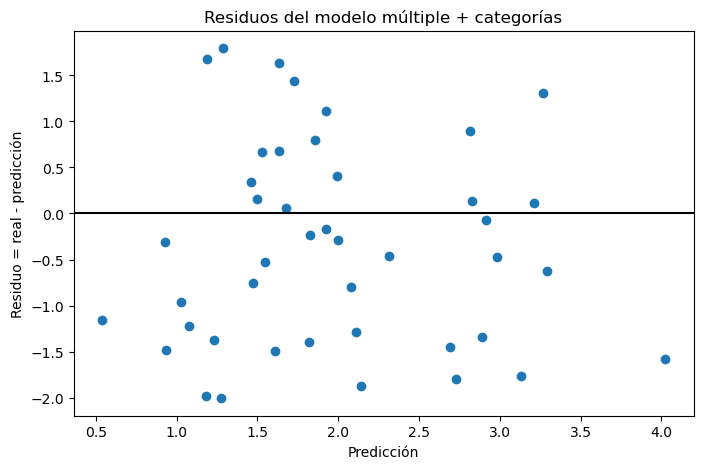

In [45]:
residuos_cat = y_val_c - pred_cat_val

plt.figure(figsize=(8, 5))

plt.scatter(
    pred_cat_val,
    residuos_cat
)

plt.axhline(0, color='black')

plt.xlabel('Predicción')
plt.ylabel('Residuo = real - predicción')
plt.title('Residuos del modelo múltiple + categorías')

plt.show()

In [46]:
pred_cat_test = modelo_cat.predict(X_test_c)
evaluacion_final = pd.DataFrame({
    'Train': metricas_regresion(
        y_train_c,
        pred_cat_train
    ),
    'Validation': metricas_regresion(
        y_val_c,
        pred_cat_val
    ),
    'Test': metricas_regresion(
        y_test_c,
        pred_cat_test
    )
}).T.round(3)

evaluacion_final

,MAE,RMSE,R2,Bias
Train,0.859,1.107,0.312,-0.000
Validation,0.979,1.150,0.233,0.364
Test,0.830,0.997,0.369,0.230


# 10. Evaluación final del modelo

| Conjunto | MAE | RMSE | R² | Bias |
|---|---:|---:|---:|---:|
| Train | 0.859 | 1.107 | 0.312 | 0.000 |
| Validation | 0.979 | 1.150 | 0.233 | 0.364 |
| Test | 0.830 | 0.997 | 0.369 | 0.230 |

### ¿Qué observamos?

El comportamiento entre los tres conjuntos es relativamente parecido.

- **Train:** el modelo explica aproximadamente el **31.2 %** de la variabilidad.
- **Validation:** baja a aproximadamente **23.3 %**.
- **Test:** obtiene aproximadamente **36.9 %**.

Los errores también se mantienen cercanos:

- MAE entre aproximadamente `0.83` y `0.98`.
- RMSE entre aproximadamente `1.00` y `1.15`.

Esto indica que no existe una diferencia extrema entre Train y los datos no utilizados
para entrenar, por lo que **no observamos un overfitting fuerte**.

### ¿Por qué Test salió mejor que Train y Validation?

No existe una regla que diga que Test obligatoriamente debe ser peor.

Como los datos fueron separados aleatoriamente, el conjunto Test puede contener
observaciones que resultaron más sencillas de predecir.

Lo importante es que los resultados sean razonablemente consistentes entre los conjuntos.

### Bias

- Train ≈ `0` → los errores positivos y negativos se compensan.
- Validation = `0.364`
- Test = `0.230`

En Validation y Test aparece una pequeña tendencia a **sobreestimar** el crecimiento.

### Conclusión

La regresión múltiple con variables numéricas, región y sector funciona mejor que
la regresión simple y mantiene un comportamiento razonablemente estable en datos nuevos.

Sin embargo, un $R^2$ alrededor de `0.37` en Test también nos indica que todavía queda
una parte importante del comportamiento del crecimiento que el modelo lineal no logra explicar.

# 11. Probando nuestro mejor modelo

Hasta ahora entrenamos y evaluamos diferentes modelos.

Nuestro mejor modelo fue la **regresión lineal múltiple con variables categóricas**, utilizando información como:

- inversión;
- exportaciones;
- precio del petróleo;
- índice de confianza;
- inflación;
- desempleo;
- región;
- sector.

Ahora podemos utilizar ese modelo para realizar una predicción sobre una observación nueva.

Por ejemplo:

> ¿Qué crecimiento estimaría el modelo para el sector Industria de la región Costa bajo determinadas condiciones económicas?

El modelo recibirá los nuevos valores de entrada $X$ y calculará:

$$
\hat y
$$

que representa el crecimiento estimado.

---

## ¿Cómo sabemos si la predicción es razonable?

Que el modelo produzca un número no significa automáticamente que la predicción sea confiable.

Podemos revisar varios aspectos.

### 1. ¿El nuevo dato se parece a los datos utilizados para entrenar?

Es más razonable confiar en una predicción cuando los nuevos valores se encuentran dentro de rangos que el modelo ya observó.

Por ejemplo, si durante el entrenamiento la inversión estuvo aproximadamente entre:

$$
100 \text{ y } 500
$$

millones, una nueva observación de:

$$
180
$$

millones está dentro de un rango conocido.

Pero si preguntamos por:

$$
5000
$$

millones, estaríamos realizando una **extrapolación**.

El modelo puede producir una respuesta, pero tenemos mucha menos evidencia de que sea válida.

---

### 2. ¿La región y el sector ya existían en Train?

Nuestro modelo aprendió utilizando categorías como:

- Costa;
- Sierra;
- Insular;
- Amazonía;

y diferentes sectores.

Si queremos predecir:

> Costa + Industria

y esas categorías estuvieron presentes durante el entrenamiento, el modelo puede utilizar los coeficientes que aprendió para ellas.

Una categoría completamente nueva que nunca apareció durante el entrenamiento requeriría un tratamiento diferente.

---

## ¿Podemos estimar cuánto podría equivocarse?

Sí, podemos utilizar las métricas obtenidas con datos que el modelo no utilizó para entrenarse.

Nuestro modelo obtuvo aproximadamente en **Test**:

- MAE = `0.83`
- RMSE = `1.00`

Esto nos da una referencia del tamaño habitual de los errores.

### MAE

Un MAE de:

$$
0.83
$$

significa que, en promedio, las predicciones se alejaron aproximadamente:

**0.83 puntos porcentuales**

del valor real.

### RMSE

Un RMSE cercano a:

$$
1.00
$$

indica que el error típico, dando mayor importancia a errores grandes, está alrededor de:

**1 punto porcentual**.

Por ejemplo, si nuestro modelo predice:

$$
\hat y = 2.5\%
$$

podríamos decir de manera orientativa:

> El modelo estima un crecimiento de **2.5 %**, pero en datos de Test sus errores estuvieron alrededor de **0.8–1 punto porcentual**.

Por tanto, una referencia sencilla podría ser pensar en valores aproximadamente alrededor de:

$$
2.5 \pm 1.0
$$

es decir:

$$
1.5\% \text{ a } 3.5\%
$$

> Este rango es solamente una **referencia basada en el error histórico del modelo**.  
> No es todavía un intervalo de predicción estadístico formal.

---

## ¿Cómo corroborar posteriormente la predicción?

Cuando conozcamos el valor real del período podemos comparar:

$$
error = y - \hat y
$$

Por ejemplo:

Predicción:

$$
\hat y = 2.5
$$

Valor real posteriormente observado:

$$
y = 2.9
$$

Entonces:

$$
error = 2.9 - 2.5 = 0.4
$$

Podemos registrar estos errores para comprobar si el modelo continúa funcionando de manera similar en el tiempo.

Si los errores comienzan a aumentar de forma constante, puede ser necesario:

- revisar los datos;
- incorporar nuevas variables;
- volver a entrenar el modelo;
- o utilizar otro tipo de modelo.

---

## Importante

Nuestra predicción actual es una **predicción condicionada a un escenario**.

Es decir:

> Si conocemos o suponemos inversión, exportaciones, petróleo, inflación, desempleo, confianza, región y sector, el modelo estima el crecimiento.

El modelo todavía no está prediciendo automáticamente cuáles serán esas variables el próximo mes.

Eso correspondería a un problema de **forecasting o series temporales**, que requiere un enfoque diferente.

In [47]:
# Creamos una nueva observación con las mismas columnas
# utilizadas para entrenar el modelo.
nuevo_dato = pd.DataFrame(
    0.0,
    index=[0],
    columns=X_cat.columns
)

# Condiciones económicas del escenario.
nuevo_dato.loc[0, 'inversion_mill'] = 180
nuevo_dato.loc[0, 'exportaciones_mill'] = 500
nuevo_dato.loc[0, 'precio_petroleo_usd'] = 70
nuevo_dato.loc[0, 'indice_confianza'] = 60
nuevo_dato.loc[0, 'inflacion_pct'] = 2.5
nuevo_dato.loc[0, 'desempleo_pct'] = 4.5

# Variables categóricas.
nuevo_dato.loc[0, 'region_Costa'] = 1
nuevo_dato.loc[0, 'sector_Industria'] = 1

nuevo_dato

,inversion_mill,precio_petroleo_usd,exportaciones_mill,indice_confianza,inflacion_pct,desempleo_pct,region_Costa,region_Insular,region_Sierra,sector_Comercio,sector_Industria,sector_Servicios
0,180.0,70.0,500.0,60.0,2.5,4.5,1.0,0.0,0.0,0.0,1.0,0.0


In [48]:
prediccion_nueva = modelo_cat.predict(nuevo_dato)[0]

print(
    'Crecimiento estimado:',
    round(prediccion_nueva, 2),
    '%'
)

Crecimiento estimado: 3.57 %


In [49]:
casos_similares = df_limpio[
    (df_limpio['region'] == 'Costa') &
    (df_limpio['sector'] == 'Industria')
]

casos_similares[
    [
        'fecha',
        'inversion_mill',
        'exportaciones_mill',
        'precio_petroleo_usd',
        'indice_confianza',
        'inflacion_pct',
        'desempleo_pct',
        'crecimiento_actividad_pct'
    ]
].sort_values(
    'crecimiento_actividad_pct',
    ascending=False
)

,fecha,inversion_mill,exportaciones_mill,precio_petroleo_usd,indice_confianza,inflacion_pct,desempleo_pct,crecimiento_actividad_pct
240,2024-01-01,173.12,429.10,68.13,38.070,1.58,4.23,4.46
164,2022-06-01,147.69,370.81,45.89,48.050,1.64,6.23,4.19
116,2021-06-01,130.69,397.49,65.03,46.970,1.90,5.52,3.87
96,2021-01-01,159.65,427.85,54.42,53.850,0.55,4.74,3.60
180,2022-10-01,153.06,367.11,36.69,39.390,0.93,6.45,3.47
260,2024-06-01,168.91,472.71,53.89,42.640,1.07,4.62,3.33
252,2024-04-01,141.07,455.91,55.92,44.925,3.44,5.50,2.85
64,2020-05-01,132.28,347.42,42.97,40.500,1.55,6.47,2.65
236,2023-12-01,167.41,408.86,66.93,52.870,0.87,5.57,2.29
272,2024-09-01,165.81,475.58,49.39,48.270,2.93,5.36,2.15


In [50]:
casos_similares['crecimiento_actividad_pct'].describe()

count    20.00000
mean      2.06850
std       1.52875
min      -1.19000
25%       1.32250
50%       1.97000
75%       3.36500
max       4.46000
Name: crecimiento_actividad_pct, dtype: float64

# 12. Reto de cierre — nuevo dataset, mismo método

Ahora **no uses `df_limpio`**. Carga `actividad_economica_reto.csv`, que está en la carpeta `datos/`. Tiene estructura parecida, pero observaciones distintas y algunos problemas de calidad.

Tu tarea es reconstruir el flujo sin copiar ciegamente:

1. cargar el CSV y convertir `fecha`;
2. explicar qué representa una fila;
3. revisar `shape`, tipos, nulos, duplicados y rangos;
4. elegir una X y construir una regresión simple;
5. separar Train/Validation/Test;
6. crear un baseline;
7. medir MAE, RMSE, Bias y R²;
8. construir un modelo múltiple;
9. agregar `region` y `sector` mediante one-hot;
10. encontrar las 5 observaciones con mayor error absoluto en Validation;
11. revisar a qué región/sector pertenecen;
12. explicar si la mejora parece predictiva o podría ser un ajuste aparente;
13. escribir al menos una limitación.

### Preguntas de comprensión

- ¿Qué diferencia existe entre parámetro e hiperparámetro?
- ¿Qué aprende exactamente `LinearRegression.fit()`?
- ¿Por qué Test no debe usarse para escoger variables?
- ¿Qué significa un coeficiente positivo?
- ¿Cuándo el intercepto tiene interpretación y cuándo es solo una pieza matemática?
- ¿Por qué un coeficiente no prueba causalidad?
- ¿Cuándo mirarías MAE y cuándo prestarías especial atención a RMSE?
- ¿Por qué una categoría nominal no debería codificarse 1, 2, 3 arbitrariamente?

In [51]:
# Punto de partida del reto. A partir de aquí escribe tus propias celdas.
df_reto = pd.read_csv(DATA_DIR / 'actividad_economica_reto.csv')
df_reto['fecha'] = pd.to_datetime(df_reto['fecha'])

df_reto.head()

,fecha,region,sector,inflacion_pct,desempleo_pct,exportaciones_mill,inversion_mill,precio_petroleo_usd,indice_confianza,crecimiento_actividad_pct,tipo_dato
0,2022-01-01,Costa,Agro,1.25,6.44,395.43,101.16,65.96,46.16,1.58,SINTETICO_DIDACTICO_RETO
1,2022-01-01,Sierra,Comercio,2.09,5.73,359.73,105.84,63.93,46.50,1.58,SINTETICO_DIDACTICO_RETO
2,2022-01-01,Amazonía,Servicios,2.47,4.92,316.24,104.90,63.38,49.44,1.10,SINTETICO_DIDACTICO_RETO
3,2022-01-01,Insular,Agro,2.52,5.99,308.88,120.31,64.41,41.31,1.31,SINTETICO_DIDACTICO_RETO
4,2022-02-01,Costa,Agro,2.80,6.28,363.29,111.08,73.26,43.74,0.55,SINTETICO_DIDACTICO_RETO


## Checklist que debe quedar para cualquier problema nuevo

Antes de modelar, deberías poder contestar:

- ¿qué quiero predecir exactamente?
- ¿qué representa una fila?
- ¿qué información estará disponible al momento real de predecir?
- ¿hay nulos, duplicados, outliers o rangos imposibles?
- ¿qué variables son numéricas y cuáles categóricas?
- ¿existe un baseline?
- ¿cómo separaré Train/Validation/Test?
- ¿qué métrica representa mejor el costo real del error?
- ¿estoy evaluando asociación/predicción o haciendo una pregunta causal?